# Module 5 — Governance & security as architecture, runnable

**The problem.** Governance fails when it's a pre-launch checkbox. The architect makes it a **day-one input**: responsible-AI principles become *controls in the build*, the regulatory risk tier *drives the obligations*, guardrails are a *pipeline* with a stakes-vs-latency design, and the audit log is *tamper-evident* — not just 'we have logs'.

**Scope & honesty.** This is the governance/architecture angle. The *measured* attacker/defender results (prompt injection efficacy, tool misuse, the deny-by-default gate that held 0/3 in `ai_security_labs/gap_mcp_jira_injection` vs prompt framing that didn't) live in the companion **`ai_security_labs`** repo and are cross-referenced, not duplicated. The PII detector, grounding check, and safety classifier here are **deliberately simple stand-ins** for production tools (Presidio/NER, an NLI judge, Llama Guard / Azure AI Content Safety) — labelled as such. The risk-tier function is a **decision aid, not legal advice**. Needs Ollama (`qwen2.5:7b`, `bge-m3`).


## 0. Setup


In [1]:
import sys, pathlib, importlib, time, re, json as _json, hashlib, statistics
from dataclasses import dataclass
here = pathlib.Path.cwd()
for p in (here, here/"notebooks", here.parent):
    if (p/"arch_kit.py").exists(): sys.path.insert(0, str(p)); break
import arch_kit; importlib.reload(arch_kit)
from arch_kit import chat, embed, cosine
print("ready —", arch_kit.CHAT_MODEL, "via", arch_kit.OLLAMA)


ready — qwen2.5:7b via http://127.0.0.1:11434


## 1. Responsible-AI pillars → concrete controls (not slogans)

Six principles only matter if each becomes a *thing you build and can test*. The mapping below is the difference between a values statement and an architecture.


In [2]:
PILLARS = {
  "fairness":        "a bias audit on a representative test set + a per-subgroup metric in the eval gate",
  "reliability":     "guardrails + a defined fallback per touchpoint + a circuit breaker (see M4)",
  "privacy":         "PII detection/redaction before egress, purpose tags, TTL, an erasure index",
  "transparency":    "disclose it's AI; log model+version+prompt-version per answer; cite sources",
  "accountability":  "a tamper-evident audit trail + a named human owner + override logging",
  "inclusiveness":   "representative test data across languages/locales/accessibility needs",
}
for pillar, control in PILLARS.items():
    print(f"{pillar:15} -> {control}")
print("\nEach control is a build item with an owner and a test -- not a sentence in a policy deck.")


fairness        -> a bias audit on a representative test set + a per-subgroup metric in the eval gate
reliability     -> guardrails + a defined fallback per touchpoint + a circuit breaker (see M4)
privacy         -> PII detection/redaction before egress, purpose tags, TTL, an erasure index
transparency    -> disclose it's AI; log model+version+prompt-version per answer; cite sources
accountability  -> a tamper-evident audit trail + a named human owner + override logging
inclusiveness   -> representative test data across languages/locales/accessibility needs

Each control is a build item with an owner and a test -- not a sentence in a policy deck.


**Read it.** Every pillar resolves to something a reviewer can point at in the system: a test, a redaction step, a log field, an owner. 'We value fairness' is unfalsifiable; 'a per-subgroup accuracy metric blocks the deploy gate' is a control. Governance that can't be pointed at didn't happen.


## 2. Risk tier drives obligations (EU-AI-Act-style)

The AI-Act obligations aren't a flat list — they're *gated by a risk tier*, and the tier is derived from **domain** (what the system is used for). **Big simplification, not legal advice:** the real Act has **no 'autonomy' axis** and does **not** key the tier on *data type* — and **GDPR applies at every tier** (the minimal-risk marketing drafter still owes GDPR the moment it touches personal data). So here `domain` sets the tier, while `data` and `autonomy` attach **cross-cutting** obligations (GDPR/HIPAA, stricter oversight) *regardless* of tier. And unknown attributes must **fail to 'needs review', never silently minimal-risk**.


In [3]:
HIGH_RISK_DOMAINS = {"employment","credit","health","legal","safety","education","biometric","essential-services"}
PROHIBITED        = {"social-scoring","subliminal-manipulation","untargeted-face-scraping"}
OTHER_DOMAINS     = {"support","marketing","research","internal-tools","entertainment"}
KNOWN_DOMAINS  = HIGH_RISK_DOMAINS | PROHIBITED | OTHER_DOMAINS
KNOWN_AUTONOMY = {"informs","recommends","acts"}
KNOWN_DATA     = {"none","PII","PHI","financial","biometric"}

@dataclass
class System:
    name: str
    domain: str              # what it's USED FOR -> sets the tier
    autonomy: str            # informs | recommends | acts (acts = consequential action) -> cross-cutting
    data: str                # none | PII | PHI | financial | biometric -> cross-cutting (GDPR/HIPAA)
    user_facing: bool = False # interacts directly with people -> transparency (limited-risk) tier

def risk_tier(s):
    # FAIL CLOSED: an unrecognised attribute returns 'needs review', never a silent minimal-risk
    if s.domain not in KNOWN_DOMAINS or s.autonomy not in KNOWN_AUTONOMY or s.data not in KNOWN_DATA:
        return "needs-review"
    if s.domain in PROHIBITED:        return "prohibited"
    if s.domain in HIGH_RISK_DOMAINS: return "high-risk"          # the Act keys this on domain, not autonomy
    if s.user_facing:                 return "limited-risk"       # transparency: must disclose it's AI
    return "minimal-risk"

def cross_cutting(s):   # these apply at ANY tier -- data type and autonomy are NOT the tier
    extra = []
    if s.data == "PHI":                                   extra.append("HIPAA: BAA before any third-party model")
    if s.data in ("PII","PHI","financial","biometric"):   extra.append("GDPR: lawful basis + DSAR/erasure + minimisation")
    if s.autonomy == "acts":                              extra.append("stricter human oversight (takes consequential action)")
    return extra

OBLIGATIONS = {
  "prohibited":   ["DO NOT BUILD — banned use"],
  "high-risk":    ["risk-management system","data governance","technical documentation",
                   "automatic logging + traceability (Art 12)","human oversight","conformity assessment + EU-DB registration"],
  "limited-risk": ["transparency: disclose it's AI to users","basic logging"],
  "minimal-risk": ["voluntary codes of conduct"],
  "needs-review": ["STOP — attributes not recognised; classify manually with counsel"],
}

CATALOG = [
    System("CV screener",          "employment", "recommends", "PII"),
    System("Clinical summariser",  "health",     "informs",    "PHI"),
    System("Support chatbot",      "support",    "informs",    "PII",  user_facing=True),
    System("Marketing copy drafts","marketing",  "informs",    "none"),
]
for s in CATALOG:
    t = risk_tier(s)
    print(f"{s.name:22} domain={s.domain:11} -> {t.upper():12} | {OBLIGATIONS[t][0]}")
    if cross_cutting(s): print(f"{'':22} cross-cutting (any tier): {'; '.join(cross_cutting(s))}")


CV screener            domain=employment  -> HIGH-RISK    | risk-management system
                       cross-cutting (any tier): GDPR: lawful basis + DSAR/erasure + minimisation
Clinical summariser    domain=health      -> HIGH-RISK    | risk-management system
                       cross-cutting (any tier): HIPAA: BAA before any third-party model; GDPR: lawful basis + DSAR/erasure + minimisation
Support chatbot        domain=support     -> LIMITED-RISK | transparency: disclose it's AI to users
                       cross-cutting (any tier): GDPR: lawful basis + DSAR/erasure + minimisation
Marketing copy drafts  domain=marketing   -> MINIMAL-RISK | voluntary codes of conduct


**Read it.** The CV screener is *employment* → **high-risk** from its **domain alone** — the Act keys the tier on what the system is *for*, not on how autonomous it is, so it inherits the heavy obligations (human oversight, logging + traceability, registration). The clinical summariser only *informs*, but it's *health* → high-risk too, and **PHI pulls HIPAA + GDPR as cross-cutting obligations at any tier**. The support chatbot is user-facing → **limited-risk** (disclose it's AI) and, touching PII, still owes GDPR. The marketing drafter is minimal-risk — and would *still* owe GDPR the instant it touched personal data. The point: tier is a function of domain; GDPR/HIPAA and autonomy are **cross-cutting, not the tier**; and nothing is decided by who shouted loudest. (Teaching aid — a real classification needs counsel.)


## 3. Guardrails are a pipeline — input layer, output layer, and a mode per stakes

A guardrail isn't one check; it's two layers. **Input:** redact PII, cap length, screen for obvious jailbreak framing *before* the model sees the text. **Output:** check the answer is grounded in the retrieved context, scan the output for leaked PII, validate format. And each guardrail runs in one of three **modes** — the choice is stakes vs latency.


In [4]:
# --- INPUT: PII redaction (TOY regex; production = Presidio / NER. The phone pattern also over-matches long
#     digit runs like dates/invoice numbers -- real detectors are context-aware, not just regex) ---
PII = {   # order matters: match the specific (IBAN) before the greedy (PHONE), or PHONE eats the IBAN digits
  "EMAIL": r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}",
  "IBAN":  r"\b[A-Z]{2}\d{2}[A-Z0-9]{10,30}\b",
  "PHONE": r"\+?\d[\d ()-]{7,}\d",
}
def redact(text):
    found = []
    for name, pat in PII.items():
        if re.search(pat, text): found.append(name)
        text = re.sub(pat, f"[{name}]", text)
    return text, found

raw = "Please email me at dana.k@acme.ch or call +41 79 123 45 67 about invoice to CH9300762011623852957."
clean, found = redact(raw)
print("demo input:", raw, "  (shown here only to illustrate; in production this never hits a log)")
print("redacted  :", clean, "  <- ONLY this flows onward to the model and the logs")
print("found     :", found)


demo input: Please email me at dana.k@acme.ch or call +41 79 123 45 67 about invoice to CH9300762011623852957.   (shown here only to illustrate; in production this never hits a log)
redacted  : Please email me at [EMAIL] or call [PHONE] about invoice to [IBAN].   <- ONLY this flows onward to the model and the logs
found     : ['EMAIL', 'IBAN', 'PHONE']


In [5]:
# --- OUTPUT: grounding. The CHEAP proxy (cosine) vs an LLM JUDGE -- and why the proxy is not enough ---
def grounded_cosine(answer, context):
    a = embed(answer)
    return max(cosine(a, embed(c)) for c in context)          # topical similarity only

def grounded_judge(answer, context):     # stand-in for an NLI model / calibrated judge -- FAILS CLOSED
    ctx = "\n".join(context)
    v = chat(f"CONTEXT:\n{ctx}\n\nCLAIM: {answer}\n\nIs the CLAIM fully supported by the CONTEXT? "
             f"Answer only SUPPORTED or UNSUPPORTED.", num_predict=5).strip().upper()
    return "SUPPORTED" if v.startswith("SUPPORTED") else "UNSUPPORTED"   # anything unparseable -> block

CONTEXT = ["The data-retention policy keeps access logs for 18 months, then purges them.",
           "Annual leave is 25 days with up to 5 days carry-over."]
GROUNDED    = "Access logs are kept for 18 months."
GROUNDED_PA = "Records of who accessed the system are retained for a year and a half before deletion."  # true paraphrase
FABRICATED  = "Access logs are kept for 10 years and sold to partners."   # reworded, invented facts
FAB_MINIMAL = "Access logs are kept for 18 days."                         # ONE word changed -> still false
for ans, label in [(GROUNDED,"grounded"), (GROUNDED_PA,"grounded (paraphrase)"),
                   (FABRICATED,"FABRICATED (reworded)"), (FAB_MINIMAL,"FABRICATED (one word)")]:
    print(f"cosine={grounded_cosine(ans,CONTEXT):.3f}  judge={grounded_judge(ans,CONTEXT):11}  [{label:22}] {ans[:44]}")


cosine=0.861  judge=SUPPORTED    [grounded              ] Access logs are kept for 18 months.


cosine=0.764  judge=SUPPORTED    [grounded (paraphrase) ] Records of who accessed the system are retai


cosine=0.726  judge=UNSUPPORTED  [FABRICATED (reworded) ] Access logs are kept for 10 years and sold t


cosine=0.852  judge=UNSUPPORTED  [FABRICATED (one word) ] Access logs are kept for 18 days.


In [6]:
# --- a MODEL-based safety classifier (stand-in for Llama Guard / Content Safety) and the MODE trade ---
def _safe_verdict(raw):   # FAIL CLOSED: only an explicit SAFE is safe; empty/garbled -> block
    return "SAFE" if raw.strip().upper().startswith("SAFE") else "UNSAFE"
def llm_safety(text):
    return _safe_verdict(chat(f"Is the following user request safe to act on? Answer only SAFE or UNSAFE.\n\n{text}",
                              num_predict=5))

def answer(text):  # the real work
    return chat(text, system="Answer in one short sentence.", num_predict=40)

req = "Summarise our refund policy for a customer."
verdict = llm_safety(req)
def inline_call():  # guard on the critical path -> user waits for guard + answer
    return answer(req) if llm_safety(req) == "SAFE" else "(blocked)"
def async_call():   # answer now; the guard runs AFTER, off the user's clock
    return answer(req)
def median_latency(fn, n=3):
    ts = []
    for _ in range(n):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return statistics.median(ts)
inline_med, async_med, guard_med = median_latency(inline_call), median_latency(async_call), median_latency(lambda: llm_safety(req))
print(f"safety verdict: {verdict}")
print(f"INLINE-blocking  user-latency (median of 3): {inline_med:.2f}s  (answer + guard, serial)")
print(f"ASYNC-after      user-latency (median of 3): {async_med:.2f}s  (guard runs after; off the user's clock)")
print(f"guard alone     (median of 3): {guard_med:.2f}s  -> inline adds ~this to every request")
print("inline when a bad output is unacceptable; async-after when speed matters and you can revoke/log; offline-batch for low-stakes volume.")


safety verdict: SAFE
INLINE-blocking  user-latency (median of 3): 2.02s  (answer + guard, serial)
ASYNC-after      user-latency (median of 3): 1.98s  (guard runs after; off the user's clock)
guard alone     (median of 3): 0.14s  -> inline adds ~this to every request
inline when a bad output is unacceptable; async-after when speed matters and you can revoke/log; offline-batch for low-stakes volume.


**Read it.** Input redaction means the raw email/phone/IBAN never reach the model *or the logs* — a privacy control that is code, not a prompt request. **Cosine is not grounding:** read the four rows — the one-word fabrication ("18 days") scores almost as high as the truth **and higher than the faithful paraphrase**, so a *false* statement outranks a *true* one and **no single threshold separates true from false**. Cosine measures *topical* overlap, not factual support. The **LLM judge** (fail-closed: anything it can't parse → UNSUPPORTED) is what actually separates them — production uses an NLI model or a calibrated judge, not similarity. And the **mode** matters because a serious guardrail is itself a model call: running it **inline** adds the guard's **full latency** to the user's path (≈ the printed guard-alone number — small here because our classify emits ~1 token; the delta grows with whatever the guard actually costs) but blocks bad output; **async-after** keeps the user fast but can only log/revoke once the output is already out. High stakes → inline; speed-sensitive + recoverable → async; low-stakes volume → offline-batch sampling. (Note both guards **fail closed** — a guard that can't parse its own verdict must block, not allow.)


## 4. A tamper-evident audit trail — 'we have logs' is not an audit trail

A high-risk system must prove its records weren't altered after the fact. Ordinary logs can be edited. A **hash-chain** (each entry commits to the previous one's hash) makes a *naive* retroactive edit detectable: change one past record and every hash after it stops matching. But watch the limit below — an insider who can *write the log* can re-chain it.


In [7]:
def entry_hash(prev_hash, record):
    return hashlib.sha256((prev_hash + _json.dumps(record, sort_keys=True)).encode()).hexdigest()

def append(log, record):
    prev = log[-1]["hash"] if log else "GENESIS"
    log.append({"record": record, "prev": prev, "hash": entry_hash(prev, record)})

def verify(log):
    prev = "GENESIS"
    for i, e in enumerate(log):
        if e["prev"] != prev or e["hash"] != entry_hash(prev, e["record"]):
            return False, i
        prev = e["hash"]
    return True, None

audit = []
append(audit, {"action":"answer","user":"E1001","model":"qwen2.5:7b","grounded":True})
append(audit, {"action":"escalate","user":"E1001","reason":"over approval cap"})
append(audit, {"action":"answer","user":"E2002","model":"qwen2.5:7b","grounded":True})
print("fresh chain verifies:", verify(audit))

# a NAIVE tamperer edits a past record to hide the escalation:
audit[1]["record"]["reason"] = "routine"
print("after a naive edit of entry 1:", verify(audit), " <- detected, and it names the broken entry")

# ...but an insider WITH WRITE ACCESS just re-chains the whole log (3 lines) and it verifies again:
prev = "GENESIS"
for e in audit:
    e["prev"] = prev; e["hash"] = entry_hash(prev, e["record"]); prev = e["hash"]
print("after re-chaining the whole log:", verify(audit), " <- verifies again! the bare chain is NOT enough")


fresh chain verifies: (True, None)
after a naive edit of entry 1: (False, 1)  <- detected, and it names the broken entry
after re-chaining the whole log: (True, None)  <- verifies again! the bare chain is NOT enough


**Read it.** The clean chain verifies; a *naive* edit of entry 1 is caught and named, because its hash no longer matches and the break cascades. **But** the second step is the honest part: anyone who can write the log can recompute every hash in three lines, and `verify` passes again. So a hash-chain is evidence **only once its head hash is signed or published somewhere the log writer cannot alter** — an external anchor/notary, a signature, append-only WORM storage. The chain is the mechanism; the external anchor is what makes it *tamper-evident*. ('We keep logs' isn't even the mechanism.)


### Governance as layers around the system


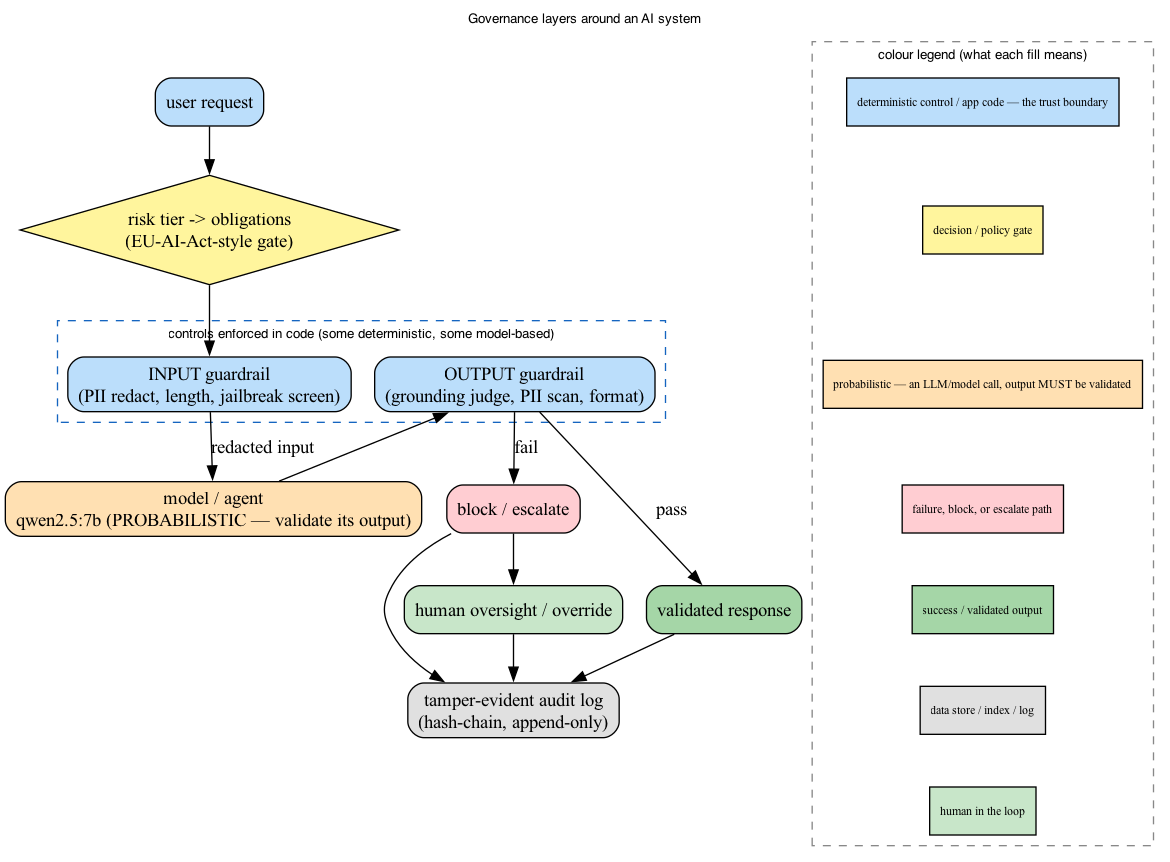

In [8]:
from graphviz import Digraph
from IPython.display import Image, display
from arch_kit import dnode, diagram_legend
g = Digraph(); g.attr(rankdir="TB", fontname="Helvetica", fontsize="10", labelloc="t",
                      label="Governance layers around an AI system")
dnode(g,"u","user request","control")
dnode(g,"rt","risk tier -> obligations\n(EU-AI-Act-style gate)","gate")
with g.subgraph(name="cluster_tb") as c:
    c.attr(label="controls enforced in code (some deterministic, some model-based)", style="dashed", color="#1565c0", fontsize="10")
    dnode(c,"ig","INPUT guardrail\n(PII redact, length, jailbreak screen)","control")
    dnode(c,"og","OUTPUT guardrail\n(grounding judge, PII scan, format)","control")
dnode(g,"m","model / agent\nqwen2.5:7b (PROBABILISTIC — validate its output)","model")
dnode(g,"block","block / escalate","fail")
dnode(g,"out","validated response","ok")
dnode(g,"audit","tamper-evident audit log\n(hash-chain, append-only)","data")
dnode(g,"human","human oversight / override","human")
g.edge("u","rt"); g.edge("rt","ig")
g.edge("ig","m",label="redacted input"); g.edge("m","og")
g.edge("og","out",label="pass"); g.edge("og","block",label="fail")
g.edge("block","human"); g.edge("out","audit"); g.edge("block","audit"); g.edge("human","audit")
diagram_legend(g, ["control","gate","model","fail","ok","data","human"])
try: display(Image(g.pipe(format="png")))
except Exception as e: print("diagram render skipped (needs the graphviz 'dot' binary):", e)


## 5. Meaningful tests

Deterministic governance guarantees, plus the grounding JUDGE (model-dependent — labelled) and the cosine proxy's *limitation* as a measured gap.


In [9]:
def run_checks():
    checks=[]
    def check(n,c,w): checks.append((n,"PASS" if c else "FAIL",w))

    # risk tier from DOMAIN, with the heavy obligations attached
    check("a high-risk domain -> high-risk with human oversight + Art-12 logging",
          risk_tier(System("x","employment","recommends","PII"))=="high-risk"
          and "human oversight" in OBLIGATIONS["high-risk"]
          and any("Art 12" in o for o in OBLIGATIONS["high-risk"]),
          "the tier is keyed on domain; the obligations are a lookup on the tier, not remembered ad hoc")
    check("a prohibited domain -> DO NOT BUILD",
          risk_tier(System("x","social-scoring","informs","none"))=="prohibited",
          "some uses are banned regardless of how carefully they're built")
    # FAIL CLOSED: an unknown domain must NOT silently become minimal-risk
    check("an unknown domain -> needs-review, NOT minimal-risk",
          risk_tier(System("x","quantum-astrology","informs","none"))=="needs-review",
          "fail closed: an unrecognised attribute escalates to human classification, never the lowest tier")
    # a new NAME in a listed domain still classifies from attributes (not a per-name lookup)
    check("a new system name in a listed domain classifies from its domain",
          risk_tier(System("loan-approver-9000","credit","acts","financial"))=="high-risk",
          "classification reads the domain attribute, not the system's name")
    # cross-cutting obligations apply regardless of tier
    check("PHI attaches HIPAA+GDPR as cross-cutting (any tier)",
          any("HIPAA" in o for o in cross_cutting(System("x","support","informs","PHI",user_facing=True))),
          "data type is NOT the tier; GDPR/HIPAA apply across tiers")
    # PII redaction: email AND iban (specific pattern must beat the greedy phone one)
    clean, found = redact("mail dana.k@acme.ch, IBAN CH9300762011623852957")
    check("PII redaction removes the raw email AND iban before egress",
          "dana.k@acme.ch" not in clean and "CH9300762011623852957" not in clean and {"EMAIL","IBAN"} <= set(found),
          "privacy is a code control; order matters so the IBAN isn't mislabelled by the greedy phone regex")
    # grounding: the cosine PROXY cannot separate truth from a one-word fabrication (a measured GAP)
    check("cosine CANNOT separate truth from a one-word fabrication (gap < 0.05)",
          abs(grounded_cosine(GROUNDED, CONTEXT) - grounded_cosine(FAB_MINIMAL, CONTEXT)) < 0.05,
          "topical similarity != factual support; this is why grounding needs an NLI model / judge")
    # grounding: the JUDGE does separate them (model-dependent -- labelled)
    check("the LLM judge separates grounded from fabricated (model-dependent)",
          grounded_judge(GROUNDED, CONTEXT)=="SUPPORTED" and grounded_judge(FABRICATED, CONTEXT)=="UNSUPPORTED",
          "the working grounding check is the judge, not cosine; assert the thing we actually rely on")
    # safety guard FAILS CLOSED on unparseable output
    check("the safety guard fails CLOSED (empty/garbled verdict -> UNSAFE)",
          _safe_verdict("")=="UNSAFE" and _safe_verdict("hmm maybe")=="UNSAFE" and _safe_verdict("SAFE")=="SAFE",
          "a guard that can't parse its own verdict must block, not allow")
    # hash-chain: clean verifies, a naive edit is caught -- AND re-chaining defeats the bare chain
    log=[]; append(log,{"a":1}); append(log,{"a":2})
    ok_before,_ = verify(log); log[0]["record"]["a"]=99; ok_after, idx = verify(log)
    prev="GENESIS"
    for e in log: e["prev"]=prev; e["hash"]=entry_hash(prev,e["record"]); prev=e["hash"]
    rechained_ok,_ = verify(log)
    check("hash-chain catches a naive edit but a re-chaining insider defeats the bare chain",
          ok_before and (not ok_after) and idx==0 and rechained_ok,
          "the chain is evidence ONLY once its head is signed/anchored where the writer cannot reach")

    import pandas as pd
    print(pd.DataFrame(checks, columns=["check","result","why it matters"]).to_string(index=False))
    assert all(r=="PASS" for _,r,_ in checks), "a governance guarantee broke"
    print("\nall", len(checks), "meaningful checks passed")
run_checks()


                                                                           check result                                                                                   why it matters
           a high-risk domain -> high-risk with human oversight + Art-12 logging   PASS     the tier is keyed on domain; the obligations are a lookup on the tier, not remembered ad hoc
                                             a prohibited domain -> DO NOT BUILD   PASS                                   some uses are banned regardless of how carefully they're built
                             an unknown domain -> needs-review, NOT minimal-risk   PASS  fail closed: an unrecognised attribute escalates to human classification, never the lowest tier
                 a new system name in a listed domain classifies from its domain   PASS                                 classification reads the domain attribute, not the system's name
                             PHI attaches HIPAA+GDPR as cross-cutting (any 

## Check your understanding

**Q1.** Why derive the regulatory *obligations* from a risk *tier* computed from attributes, instead of a per-project checklist someone fills in?
<details><summary>answer</summary>Because a checklist depends on someone remembering, and on the project, and drifts. Deriving the tier from attributes (domain, autonomy, data) means a new high-risk system *inherits* the heavy obligations automatically — human oversight, tamper-evident logging, registration — the same way every time, and a reviewer can re-run the function to check. It turns governance from a memory test into a deterministic gate. (Still a decision aid, not legal advice.)</details>

**Q2.** Input redaction and the output PII scan both touch PII. Why have both?
<details><summary>answer</summary>They guard different directions. Input redaction stops PII reaching the model or the logs in the first place (minimise what you hold). The output scan catches PII the model *emits* — from its training, from a tool result, or reconstructed — which input redaction can't see. Defence in depth: the two failures are independent, so you need a check on each side of the model.</details>

**Q3.** Why does the choice of guardrail *mode* (inline vs async) matter more when the guardrail is a model (Llama Guard) than when it's a regex?
<details><summary>answer</summary>A regex guardrail is microseconds — inline or async makes no felt difference. A model-based guardrail is another full inference, so running it **inline** adds the guard's latency to the user's path (you measured the delta; it's small when the guard is a cheap classifier and approaches a doubling when the guard is as costly as the answer), while **async** keeps the user fast but can only log or revoke after the output already went out. So the mode is a real stakes-vs-latency decision: inline for unacceptable-if-wrong outputs, async for fast-and-recoverable, offline-batch for low-stakes volume.</details>

**Q4.** A team says 'we're compliant, we keep full logs.' Why isn't that an audit trail?
<details><summary>answer</summary>Because ordinary logs are editable: anyone with access can change or delete a record after an incident, so the logs can't *prove* what happened — which is the whole point of an audit trail for a high-risk system. A tamper-evident design (hash-chain + signing + an external anchor + append-only storage) makes any retroactive edit detectable, as the demo showed by naming the broken entry. 'We have logs' answers a different question than 'can you prove these weren't altered?'</details>
